# Specification search: repeated validation

This study repeats the specification search from
[](agent_specification_search.ipynb) on independent training samples and
compares its final fit with its starting `autospec` fit. Every comparison
uses a new test sample that neither the probes nor the search can inspect.
The experiment measures predictive improvement and simplification separately,
including cases where the final specification predicts worse.

This recorded experiment teaches how to validate a complete search procedure, including
changes that make prediction worse. Independent test samples measure prediction while
the known processes measure structural recovery.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the value and cost of running specification search after autospec |
| **Observed response** | simulated continuous outcomes from four known processes |
| **Estimand** | change in independent test MSE and retained signal/noise structure between initial and final specifications |
| **Units** | squared simulated response units; term counts and elapsed seconds |
| **Sampling unit** | an independent simulated observation |
| **Dependence** | independent rows; a near-duplicate predictor in the correlated process |
| **Split / resampling unit** | fresh training and test samples per repetition; five shared inner row folds |
| **Tuning** | the existing autospec and search policy runs entirely on each training sample |
| **Uncertainty** | paired Monte Carlo standard errors across independent training/test draws |
| **Claim type** | methodological evaluation of a fixed search policy, not a claim of scientific variable discovery |
:::


## Processes and search policy

| Process | Mean function | Main difficulty |
|---|---|---|
| Linear additive | $p-0.8q+0.5r$ | two irrelevant predictors and unnecessary smoothness |
| Correlated | $\exp(0.5x_1)+0.5x_3$ | a noisy near-copy of $x_1$ can substitute for it |
| Pure interaction | $1.5\tanh(2u)\tanh(2v)+0.5w$ | the interaction has no marginal main effect |
| Small sample | $1.5a+\sin(2b)$ | 150 rows, two signals and five noise columns |

The first three processes use 400 training rows, and the last uses 150;
each new test sample has 2,000 rows. Predictor and noise distributions are
defined by the existing scenario functions in `benches/bench_agent_search.py`.
The runner reuses its `agent_loop` without modifying the acceptance policy:
it accepts an improvement exceeding two paired fold standard errors, or a
removal whose estimated cost is within two standard errors. This is a search
heuristic applied repeatedly, not a sequence of calibrated hypothesis tests.

The experiment supplies 80 fits to autospec's probes and allows three search
rounds. That budget applies to the probes only: term reports, comparisons and
final stopping searches can perform additional fits. The baseline is the
initial formula at its own selected stopping point, not an untuned default.

## Recorded experiment

The JSON file is the output of `benches/bench_specification_validation.py`,
not a model specification supplied to `gamboost`. The runner calls the
documented search once per training draw and evaluates both its initial and
final fitted models on the same fresh test sample. Saving those results keeps
the complete simulation out of the book build. The reproduction command is
at the end of this page, and this artifact accompanies the notebook download.

The next cells display the protocol stored with the results, check that every
planned run is represented, and display one result record before any
aggregation. `initial_mse` and `final_mse` are mean squared errors on the
independent test sample; `mse_change` is final minus initial. Formula counts
include candidates that the fitted boosting path may never select.

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

# Import the book's plotting style and render charts for both HTML and PDF.
from mboostrs import plot as mbplot

alt.renderers.enable("svg")

RendererRegistry.enable('svg')

In [2]:
# Read measured results and show the settings that produced them.
artifact_path = Path("bench_specification_validation.json")
document = json.loads(artifact_path.read_text())
protocol = document["protocol"]

display(Markdown("```json\n" + json.dumps(protocol, indent=2) + "\n```"))

# An interrupted run must not appear to be a completed repeated experiment.
expected_runs = document["repeats"] * len(protocol["scenarios"])
run_ids = {(row["scenario"], row["repeat"]) for row in document["results"]}
assert len(run_ids) == len(document["results"]) == expected_runs

successful = []
failed = []
for result in document["results"]:
    if result["status"] == "ok":
        successful.append(result)
    else:
        failed.append(result)

failed_count = len(failed)
display(pl.DataFrame({
    "planned runs": [expected_runs],
    "successful": [len(successful)],
    "failed": [failed_count],
}))
if failed:
    display(pl.DataFrame(failed))

```json
{
  "scenarios": [
    "linear_additive",
    "correlated",
    "pure_interaction",
    "small_n"
  ],
  "max_train_rows": 400,
  "test_rows": 2000,
  "autospec_budget": 80,
  "search_rounds": 3,
  "budget_scope": "autospec probes only; subsequent report/search/refit calls are additional",
  "inner_folds": 5,
  "outer": "fresh independent training and test draws",
  "acceptance": "existing agent_loop: improvement beyond two fold SEs, else removal within two SEs",
  "baseline": "the starting autospec formula at its own tuned mstop",
  "test_access": "only after all specification and stopping choices",
  "warmup": "none; timings include first-use costs and are descriptive"
}
```

planned runs,successful,failed
i64,i64,i64
48,48,0


In [3]:
# Show the first run by recorded order, not by how well it performed.
example_result = successful[0]
example_fields = (
    "scenario", "repeat", "seed", "n_train", "n_test", "warnings",
    "initial_formula", "final_formula", "initial_mstop", "final_mstop",
    "initial_mse", "final_mse", "mse_change", "oracle_mse",
    "initial_terms", "final_terms", "final_noise", "final_signal_found",
)
example_record = {field: example_result[field] for field in example_fields}
display(Markdown("```json\n" + json.dumps(example_record, indent=2) + "\n```"))

```json
{
  "scenario": "linear_additive",
  "repeat": 0,
  "seed": 31000,
  "n_train": 400,
  "n_test": 2000,
  "warnings": [
    "12 fold predictions in this call asked 2 learner(s) to predict outside the range they were fitted on. bbs(p), covariate p: 2 above 2.58552 (worst 0.16 training ranges out); bbs(p), covariate p: 2 below -2.22247 (worst 0.15 training ranges out); bbs(r), covariate r: 1 above 2.38082 (worst 0.11 training ranges out); bbs(r), covariate r: 1 below -2.24023 (worst 0.073 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.16 training ranges out that is an assumption, not an estimate. Pass term_report(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.",
    "3 learner(s) are asked to predict outside the range they were fitted on. bbs(p), covariate p: 2 below -3.06523 (worst 0.23 training ranges out); bbs(q), covariate q: 5 below -2.83832 and 27 above 2.3403 (worst 0.22 training ranges out); bbs(r), covariate r: 8 below -2.61676 and 2 above 2.95145 (worst 0.18 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.23 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.",
    "56 fold predictions in this call asked 3 learner(s) to predict outside the range they were fitted on. bbs(p), covariate p: 2 above 2.58552 (worst 0.16 training ranges out); bbs(p), covariate p: 2 below -2.22247 (worst 0.15 training ranges out); bbs(r), covariate r: 1 above 2.38082 (worst 0.11 training ranges out); bbs(r), covariate r: 1 below -2.24023 (worst 0.073 training ranges out); bbs(t), covariate t: 2 above 2.69584 (worst 0.066 training ranges out); bbs(t), covariate t: 1 below -3.34865 (worst 0.065 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.16 training ranges out that is an assumption, not an estimate. Pass term_report(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.",
    "8 fold predictions in this call asked 2 learner(s) to predict outside the range they were fitted on. bbs(p), covariate p: 2 above 2.58552 (worst 0.16 training ranges out); bbs(p), covariate p: 2 below -2.22247 (worst 0.15 training ranges out); bbs(r), covariate r: 1 above 2.38082 (worst 0.11 training ranges out); bbs(r), covariate r: 1 below -2.24023 (worst 0.073 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.16 training ranges out that is an assumption, not an estimate. Pass compare_specifications(extrapolation='allow') to accept it, or extrapolation='clip' to hold the effect flat outside the range instead, or extrapolation='error' to refuse. Guide: python -m mboostrs guide modeling-tactics.",
    "optimal mstop 47 is within 5% of the search cap 50; the search range was exhausted \u2014 consider increasing mstop and re-running cvrisk.",
    "optimal mstop 50 is within 5% of the search cap 50; the search range was exhausted \u2014 consider increasing mstop and re-running cvrisk."
  ],
  "initial_formula": "y ~ bbs(p, df=4.0) + bbs(q, df=4.0) + bbs(r, df=4.0) + btree(t)",
  "final_formula": "y ~ bbs(p, df=4.0) + bbs(q, df=4.0) + bbs(r, df=4.0)",
  "initial_mstop": 84,
  "final_mstop": 34,
  "initial_mse": 1.1238896341802673,
  "final_mse": 1.071777520294111,
  "mse_change": -0.05211211388615622,
  "oracle_mse": 1.0171347042487269,
  "initial_terms": 4,
  "final_terms": 3,
  "final_noise": [],
  "final_signal_found": [
    "p",
    "q",
    "r"
  ]
}
```

The record exposes both formulas and stopping points. `oracle_mse` uses the
known generating mean on those same test outcomes; it is a simulation
reference and is never available to the search. The full record additionally
retains warnings, selected learner names, the search transcript and digests.

The public calls inside each search round have this structure. `training`
contains only the training draw; `folds` is shared across candidate comparisons.
The preceding [search study](agent_specification_search.ipynb) walks through
the individual reports and the acceptance rule.

```python
# Diagnose the current formula on the training sample's inner folds.
report = mb.term_report(formula, training, folds=folds, mstop=mstop)
suggestions = mb.suggest_specifications(report, screened=screened_pairs)

# Compare proposed formulas on those same folds, then apply the stated rule.
comparison = mb.compare_specifications(
    candidates, training, "y", folds=folds, mstop=mstop,
)

# After the search ends, choose its stopping point using training data only.
tuning = mb.tune_mstop(final_formula, training, folds=folds)
```

In [4]:
# Give the stored quantities readable column labels without changing them.
records = []
for result in successful:
    records.append({
        "process": result["scenario"],
        "draw": result["repeat"],
        "initial MSE": result["initial_mse"],
        "final MSE": result["final_mse"],
        "MSE change": result["mse_change"],
        "initial terms": result["initial_terms"],
        "final terms": result["final_terms"],
        "noise columns": len(result["final_noise"]),
        "main signals recovered": len(result["final_signal_found"]),
        "true pairs": result["final_true_pairs"],
        "false pairs": result["final_false_pairs"],
        "seconds": result["seconds"],
    })

frame = pl.DataFrame(records)
display(frame.head(4))

process,draw,initial MSE,final MSE,MSE change,initial terms,final terms,noise columns,main signals recovered,true pairs,false pairs,seconds
str,i64,f64,f64,f64,i64,i64,i64,i64,i64,i64,f64
"""linear_additive""",0,1.12389,1.071778,-0.052112,4,3,0,3,0,0,0.655569
"""linear_additive""",1,1.062639,1.068212,0.005573,3,3,0,3,0,0,0.619498
"""linear_additive""",2,1.075857,1.073615,-0.002242,3,3,0,3,0,0,0.542137
"""linear_additive""",3,1.033986,1.034179,0.000193,3,3,0,3,0,0,0.551373


## Prediction and simplification

The table averages over {eval}`document['repeats']` independent draws for
each process. There are {eval}`failed_count` failed runs, shown above when
present. Negative MSE changes favor the search. The Monte Carlo standard
error is computed from the paired changes, so methods are compared on the
same test outcomes. It measures variability within these processes, with a
fixed search policy and training size.

In [5]:
# One row is one independent training/test draw. Pair the two MSEs first,
# then estimate variability across draws, not across individual test rows.
summary = (
    frame.group_by("process")
    .agg(
        pl.len().alias("draws"),
        pl.col("initial MSE").mean(),
        pl.col("final MSE").mean(),
        pl.col("MSE change").mean(),
        (pl.col("MSE change").std() / pl.len().sqrt()).alias("Monte Carlo SE"),
        (pl.col("MSE change") > 0).mean().alias("fraction worse"),
        pl.col("initial terms").mean(),
        pl.col("final terms").mean(),
    )
    .sort("process")
)
display(summary)

# Build the prose from the measured results so it stays true after a rerun.
sentences = []
for row in summary.to_dicts():
    sentences.append(
        f"For {row['process']}, mean MSE changes by {row['MSE change']:+.4f} "
        f"(Monte Carlo SE {row['Monte Carlo SE']:.4f}), with "
        f"{row['final terms']:.1f} terms retained on average."
    )
comparison_text = " ".join(sentences)

process,draws,initial MSE,final MSE,MSE change,Monte Carlo SE,fraction worse,initial terms,final terms
str,u32,f64,f64,f64,f64,f64,f64,f64
"""correlated""",12,0.510257,0.512165,0.001908,0.00136,0.583333,2.75,2.0
"""linear_additive""",12,1.043522,1.0373,-0.006222,0.004475,0.416667,3.166667,3.0
"""pure_interaction""",12,1.548189,0.281035,-1.267154,0.011752,0.0,3.75,2.0
"""small_n""",12,0.74928,0.736098,-0.013182,0.022254,0.25,2.75,2.166667


{eval}`comparison_text` A smaller formula can be useful even when predictive
error is nearly unchanged, but simplification is not automatically harmless.
The fraction of draws with higher test error records the direction of the
change; it does not distinguish negligible increases from substantial ones.

Each point below is the change on one draw. The zero line marks equal test
error; the vertical spread shows variation that a mean alone would conceal.

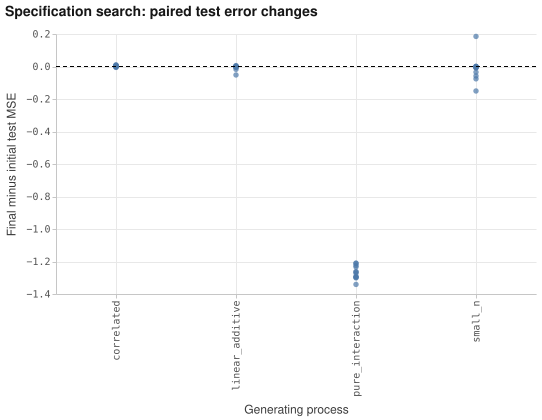

In [6]:
points = alt.Chart(frame).mark_point(filled=True).encode(
    x=alt.X("process:N", title="Generating process"),
    y=alt.Y("MSE change:Q", title="Final minus initial test MSE"),
    tooltip=["process", "draw", "MSE change", "initial terms", "final terms"],
)
zero_line = (
    alt.Chart(pl.DataFrame({"zero": [0.0]}))
    .mark_rule(strokeDash=[4, 3])
    .encode(y="zero:Q")
)
display((points + zero_line).properties(
    title="Specification search: paired test error changes", width=480, height=260,
))

## Structural recovery

Formula membership and actual boosting selection are different. The artifact
retains both. The following table counts noise columns and interactions in the
final formula, and how many generating main-effect columns it still contains.
The correlated process has no uniquely preferable empirical attribution
between a predictor and its close proxy; failure to retain the original name
alone is therefore not a complete measure of lost information. Mean-function
prediction error, retained in the artifact, provides a complementary target.

In [7]:
# Count retained structure separately from predictive error.
structure = frame.group_by("process").agg(
    pl.col("noise columns").mean(),
    pl.col("main signals recovered").mean(),
    pl.col("true pairs").mean(),
    pl.col("false pairs").mean(),
).sort("process")
display(structure)

# Removing noise from the observed response lets us score the mean function.
function_rows = []
for name in protocol["scenarios"]:
    draws = [result for result in successful if result["scenario"] == name]
    function_rows.append({
        "process": name,
        "initial mean-function MSE": np.mean([r["initial_mean_error"] for r in draws]),
        "final mean-function MSE": np.mean([r["final_mean_error"] for r in draws]),
    })
display(pl.DataFrame(function_rows))

process,noise columns,main signals recovered,true pairs,false pairs
str,f64,f64,f64,f64
"""correlated""",0.0,2.0,0.0,0.0
"""linear_additive""",0.0,3.0,0.0,0.0
"""pure_interaction""",0.0,1.0,1.0,0.0
"""small_n""",0.25,2.0,0.0,0.166667


process,initial mean-function MSE,final mean-function MSE
str,f64,f64
"""linear_additive""",0.029684,0.023109
"""correlated""",0.013684,0.014536
"""pure_interaction""",1.291442,0.028302
"""small_n""",0.105975,0.093814


## A retained search transcript

The first draw of the pure-interaction process illustrates the decisions
behind one result. It is chosen by process name and draw index, irrespective
of success. The complete artifact retains every transcript, formula, stopping
point, warning and prediction digest so that an unfavorable result can be
examined as closely as a favorable one.

In [8]:
# The example is fixed in advance by process and draw, not selected by score.
example = next((result for result in successful
                if result["scenario"] == "pure_interaction" and result["repeat"] == 0), None)

if example is not None:
    transcript_rows = []
    for step in example["transcript"]:
        decision = step.get("change", step.get("formula", step.get("spec", "scale diagnostic")))
        transcript_rows.append({
            "step": step["step"],
            "round": step.get("round"),
            "decision": decision,
            "inner risk change": step.get("delta"),
            "paired fold SE": step.get("se"),
        })
    display(pl.DataFrame(transcript_rows))

    # Show the formulas without truncating their interaction terms in a table.
    display(Markdown(
        "**Initial formula**\n\n```text\n" + example["initial_formula"]
        + "\n```\n\n**Final formula**\n\n```text\n" + example["final_formula"] + "\n```"
    ))

step,round,decision,inner risk change,paired fold SE
str,i64,str,f64,f64
"""autospec""",null,"""y ~ bols(u) + bbs(v, df=4.0) +…",null,null
"""comparison""",0,"""scale diagnostic""",null,null
"""accept""",0,"""add bbs(u, df=2.5, knots=5) %X…",-0.90867,0.06183
"""comparison""",1,"""scale diagnostic""",null,null
"""accept""",1,"""drop 3 terms that earn nothing""",0.0,0.0
"""comparison""",2,"""scale diagnostic""",null,null
"""stop""",2,"""scale diagnostic""",null,null
"""final""",null,"""bbs(w, df=4.0) + bbs(u, df=2.5…",null,null


**Initial formula**

```text
y ~ bols(u) + bbs(v, df=4.0) + bbs(w, df=4.0) + bbs(k, df=4.0)
```

**Final formula**

```text
y ~ bbs(w, df=4.0) + bbs(u, df=2.5, knots=5) %X% bbs(v, df=2.5, knots=5)
```

## Reproduction and limits

The simulation evaluates the incremental value of this specific search after
autospec. It does not compare against expert specification, another search
algorithm, or a fixed additive model with the same total compute budget.
The processes exercise linearity, correlation, interactions and small samples;
they exclude grouped outcomes, distributional family search and real-data
measurement errors. Twelve repetitions are a modest simulation, not a precise
estimate of rare failure rates. The companion [](cz_agent_search.ipynb)
examines the separate problem of prediction in unseen states.

The inner scores have been reused to select many changes. Only the external
scores above evaluate the full procedure. If the method is revised after
examining these results, a subsequent validation should use new random draws
and preferably additional processes.

Run from the repository root:

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
  .venv/bin/python -m benches.bench_specification_validation --repeats 12
```

The JSON artifact records source and binary identities, versions, seeds,
input/output digests and warnings. Workflow times include first-use costs and
are descriptive; no isolated speed comparison or peak-memory measurement is
claimed. The book reads the recorded evidence rather than rerunning the full
search on every build. For a worked distributional application, see
[](munich_rents_distributional.ipynb).